<p style="text-align: center">
<img src="../../assets/images/dtlogo.png" alt="Duckietown" width="50%">
</p>

# Guida Completa ed Intuitiva al Filtro di Kalman (KF)
### Spiegazione passo-passo "da zero" per la localizzazione di un robot mobile (Duckiebot)

Benvenuto in questo notebook! Se hai aperto questo documento, probabilmente hai già visto formule piene di matrici, trasposte, gaussiane e lettere greche che possono sembrare intimidatorie.

**Non preoccuparti:** in questa guida smonteremo **ogni singolo concetto, equazione e riga di codice** presente nel notebook originale del Filtro di Kalman pezzo per pezzo, partendo da zero. Utilizzeremo un **unico esempio numerico concreto** basato sul nostro **Duckiebot** che si muove sul pavimento di una stanza.

Alla fine di questo notebook, non solo capirai ogni singola formula matematica, ma sarai in grado di implementarla e visualizzarla con padronanza in Python.

---

### La grande domanda: Perché serve il Filtro di Kalman?

Immagina di guidare il tuo Duckiebot sul pavimento. Per sapere dove si trova il robot ad ogni secondo hai a disposizione due strumenti, ma **entrambi sono imperfetti**:

1. **La Fisica del Movimento (Odometria / Dead Reckoning):**
   * Tu conosci la cinematica del robot e quanta corrente dai ai motori delle ruote (es. "fai 5 giri al secondo"). Se moltiplichi i giri per la circonferenza della ruota, puoi stimare quanti centimetri ha percorso il robot nel tempo partendo dallo stato iniziale.
   * **Il problema:** Nel mondo reale dobbiamo sempre fare i conti con modelli imperfetti. Le ruote sul parquet o sulla pista **slittano**, il pavimento non è perfettamente liscio, le parti meccaniche presentano tolleranze e attriti.
   * **Conseguenza:** È come camminare a occhi chiusi contando i passi: all'inizio sai dove sei, ma dopo 20 passi sarai andato a sbattere contro un muro perché i piccoli errori di slittamento si **accumulano all'infinito** (fenomeno della *deriva* o *drift*).

2. **I Sensori Esterni (Telecamera, Sensori ToF/Laser, GPS):**
   * I robot sono dotati di vari sensori che possono aiutarci a stimare la loro posizione (ad esempio misurando la distanza dai muri o leggendo un cartello AprilTag).
   * **Il problema:** Anche i sensori sono imperfetti e affetti da **rumore** (riflessi di luce, jitter elettronico, risoluzione finita).
   * **Conseguenza:** Le misure "ballano" continuamente intorno al valore reale. Un istante il sensore dice che sei a $50\text{ cm}$, l'istante dopo a $53\text{ cm}$, poi a $48\text{ cm}$, anche se il robot è fermo!

### Il Superpotere del Filtro di Kalman: *Sensor Fusion* (Fusione Sensoriale)
Possiamo combinare i dati dei sensori con i modelli fisici che già possediamo per stimare meglio lo stato del robot? **È esattamente qui che il Filtro di Kalman (KF) ci aiuta!**
Se abbiamo nuovi dati dallo stato del robot insieme a una misura di quanto sono informativi (la loro *covarianza*), il KF fonde queste informazioni calcolando istante per istante **di chi fidarsi di più**, producendo una stima finale **molto più accurata e stabile di ciascuna delle due fonti prese da sole**.

---
## I Tre Assunti Fondamentali del Filtro di Kalman: Spiegazione Formula per Formula con Esempi Numerici

Nel Filtro di Kalman classico facciamo **tre assunzioni matematiche fondamentali** che governano tutto l'algoritmo. Smontiamole pezzo per pezzo capendo il significato fisico di ogni singolo simbolo e accompagnando ciascuna formula con un **esempio numerico concreto** sul nostro **Duckiebot**.

---

### 1. Processo Lineare con Rumore Gaussiano Additivo:
$$\mathbf{x}_{t} = A_t \mathbf{x}_{t-1} + B_t \mathbf{u}_{t} + \mathbf{w}_{t} \quad \text{dove} \quad \mathbf{w}_{t} \sim \mathcal{N}(0, Q_t)$$

#### A cosa serve questa formula?
Risponde alla domanda fisica: *"Come evolve la posizione reale del robot nel mondo da un secondo all'altro quando inviamo comandi ai motori?"*

#### Smontiamo ogni singolo pezzo:
* **$\mathbf{x}_t$ e $\mathbf{x}_{t-1}$ (Vettore di Stato Reale):** Rappresenta la posa del robot all'istante attuale $t$ e a quello precedente $t-1$ (es. coordinate sul pavimento $[x, y]^T$).
* **$A_t$ (Matrice di transizione di stato):** Descrive cosa fa il robot **se non tocchiamo i comandi** (inerzia o moto naturale). Se il Duckiebot lasciato senza comandi rimane esattamente fermo dov'era, $A_t$ è semplicemente la matrice identità $I$ (moltiplicare per 1):
  $$A_t = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$
* **$\mathbf{u}_t$ (Vettore di controllo):** Il comando che inviamo ai motori (ad esempio la velocità comandata alle ruote: $v_x = 5\text{ cm/s}, v_y = 0$).
* **$B_t$ (Matrice di controllo):** È il "traduttore meccanico" che converte i comandi $\mathbf{u}_t$ in spostamento effettivo sulla pista (es. moltiplica la velocità per l'intervallo di tempo $\Delta t = 1\text{ s}$ per ottenere i centimetri percorsi):
  $$B_t = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$
* **$\mathbf{w}_t$ (Rumore di processo):** L'imprevedibilità del mondo reale! Le ruote sul pavimento possono slittare, il pavimento ha piccoli avvallamenti e i motori presentano leggere tolleranze meccaniche.
* **$\mathbf{w}_t \sim \mathcal{N}(0, Q_t)$:** Significa che questo rumore segue una distribuzione normale (gaussiana) con:
  * **Media $0$:** Non sappiamo se il robot slitterà a destra o a sinistra, ma in media gli errori casuali si compensano (il robot non tira sistematicamente da una parte).
  * **Covarianza $Q_t$:** Rappresenta quanto è "scivoloso" il pavimento. Più i valori di $Q_t$ sono grandi, meno possiamo fidarci della stima del movimento.
* **Perché si dice "Lineare con Rumore Additivo"?**
  * *Lineare:* Non ci sono funzioni curve complicate (come $\sin, \cos$ o quadrati): sono tutte semplici moltiplicazioni tra matrici e vettori.
  * *Additivo:* Il rumore $\mathbf{w}_t$ entra nell'equazione come una semplice somma ($+$ alla fine).

#### 🔢 Esempio Numerico Concreto (Formula 1):
Immagina che il Duckiebot parta fermo dall'origine $\mathbf{x}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}\text{ cm}$.
Inviamo il comando di avanzare lungo $x$ a $5\text{ cm/s}$ per $\Delta t = 1\text{ s}$, quindi $\mathbf{u}_1 = \begin{bmatrix} 5 \\ 0 \end{bmatrix}$.
La covarianza dello slittamento del pavimento è nota: $Q = \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$.

Durante questo secondo, le ruote slittano leggermente e capita un disturbo reale $\mathbf{w}_1 = \begin{bmatrix} +0.4 \\ -0.1 \end{bmatrix}\text{ cm}$.
La posizione reale in cui finisce fisicamente il robot è:
$$\mathbf{x}_1 = A_1 \mathbf{x}_0 + B_1 \mathbf{u}_1 + \mathbf{w}_1 = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 0 \end{bmatrix} + \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 5 \\ 0 \end{bmatrix} + \begin{bmatrix} +0.4 \\ -0.1 \end{bmatrix} = \begin{bmatrix} 5.4 \\ -0.1 \end{bmatrix}\text{ cm}$$
*Invece di trovarsi esattamente a $(5, 0)$, a causa del rumore reale $\mathbf{w}_1$ il robot è finito fisicamente a $(5.4, -0.1)$!*

---

### 2. Modello di Misura Lineare con Rumore Gaussiano Additivo:
$$\mathbf{z}_t = H_t \mathbf{x}_t + \mathbf{n}_t \quad \text{dove} \quad \mathbf{n}_t \sim \mathcal{N}(0, R_t)$$

#### A cosa serve questa formula?
Risponde alla domanda: *"Cosa leggono fisicamente i sensori esterni (telecamera, laser) data la posizione reale $\mathbf{x}_t$ del robot?"*

#### Smontiamo ogni singolo pezzo:
* **$\mathbf{z}_t$ (Vettore di Misura):** La lettura grezza fornita dai sensori all'istante $t$ (ad esempio un raggio laser puntato sul muro che restituisce $8\text{ cm}$, oppure le coordinate rilevate da un AprilTag).
* **$\mathbf{x}_t$ (Stato Reale):** Dove si trova effettivamente il robot nello spazio.
* **$H_t$ (Matrice di Osservazione o "Traduttore"):** Proietta lo stato reale nello spazio dei sensori. Adatta le variabili e le unità di misura:
  * *Esempio:* Se lo stato ha 2 coordinate $[x, y]^T$, ma il sensore laser misura solo la distanza frontale lungo $x$, la matrice $H = \begin{bmatrix} 1 & 0 \end{bmatrix}$ fa da filtro ed estrae solo $x$, permettendo di confrontare grandezze omogenee:
    $$H \mathbf{x}_t = \begin{bmatrix} 1 & 0 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} = x$$
* **$\mathbf{n}_t$ (Rumore di Misura):** L'errore intrinseco del sensore (sfocatura dell'ottica, riflessi di luce, jitter elettrico nei circuiti).
* **$\mathbf{n}_t \sim \mathcal{N}(0, R_t)$:** Indica che l'errore del sensore è gaussiano:
  * **Media $0$:** Il sensore è tarato correttamente (non aggiunge un errore fisso sistematico di $+5\text{ cm}$).
  * **Covarianza $R_t$:** È l'incertezza del sensore dichiarata dal produttore. Più $R_t$ è piccolo, più il sensore è preciso e affidabile.
* **Perché si dice "Lineare con Rumore Additivo"?** Perché la misura attesa è una combinazione lineare dello stato ($H_t \mathbf{x}_t$) a cui si aggiunge semplicemente per somma il rumore ($+ \mathbf{n}_t$).

#### 🔢 Esempio Numerico Concreto (Formula 2):
Il Duckiebot si trova realmente nella posizione reale appena calcolata: $\mathbf{x}_1 = \begin{bmatrix} 5.4 \\ -0.1 \end{bmatrix}\text{ cm}$.
Il robot monta due sensori di distanza dalle pareti (uno lungo $x$ e uno lungo $y$), per cui la matrice di misura è l'identità:
$$H = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$
La covarianza del rumore dei sensori fornita dal costruttore è $R = \begin{bmatrix} 0.75 & 0 \\ 0 & 0.60 \end{bmatrix}$.

Quando i sensori sparano il raggio, a causa del disturbo ottico ed elettrico si genera un rumore istantaneo $\mathbf{n}_1 = \begin{bmatrix} +0.6 \\ -0.3 \end{bmatrix}\text{ cm}$.
La misura grezza che il computer di bordo riceve fisicamente è:
$$\mathbf{z}_1 = H \mathbf{x}_1 + \mathbf{n}_1 = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 5.4 \\ -0.1 \end{bmatrix} + \begin{bmatrix} +0.6 \\ -0.3 \end{bmatrix} = \begin{bmatrix} 5.4 + 0.6 \\ -0.1 - 0.3 \end{bmatrix} = \begin{bmatrix} 6.0 \\ -0.4 \end{bmatrix}\text{ cm}$$
*Il sensore restituisce $(6.0, -0.4)$, un valore vicino alla realtà $(5.4, -0.1)$ ma perturbato dal rumore di lettura $\mathbf{n}_1$!*

---

### 3. Distribuzione a Priori Gaussiana (*Prior Belief*):
$$bel(\mathbf{x}_0) = \mathcal{N}(\mu_0, \Sigma_0)$$

#### A cosa serve questa formula?
Risponde alla domanda: *"Prima ancora di accendere i motori al tempo $t=0$, cosa sappiamo di dove si trova il robot e quanto ne siamo sicuri?"*

#### Smontiamo ogni singolo pezzo:
* **$bel(\mathbf{x}_0)$ (*Belief*, credenza):** È la nostra convinzione probabilistica sullo stato iniziale.
* **$\mathcal{N}$ (Distribuzione Normale o Gaussiana):** Dice che l'incertezza ha la classica forma a campana. Il valore al centro della campana è il più probabile, mentre le probabilità sfumano man mano che ci allontaniamo dal centro.
* **$\mu_0$ (Vettore media iniziale):** Il punto esatto nello spazio in cui crediamo si trovi il robot (es. $[0, 0]^T$ se lo appoggiamo sull'origine della pista).
* **$\Sigma_0$ (Matrice di covarianza iniziale):** Misura l'ampiezza del nostro dubbio di partenza:
  * *Se posizioni il Duckiebot con un righello millimetrico:* Sei molto sicuro, quindi imposti varianze piccolissime (es. $\Sigma_0 = \text{diag}(0.1, 0.1)$).
  * *Se posizioni il robot a caso nella stanza senza guardare:* Imposti numeri enormi (es. $\Sigma_0 = \text{diag}(1000, 1000)$), dicendo al filtro: *"Non fidarti della mia stima $\mu_0$, fidati subito della prima lettura del sensore!"*.

#### 🔢 Esempio Numerico Concreto (Formula 3):
* **Caso A (Partenza con posizionamento preciso a mano):**
  Posizioni il Duckiebot esattamente sulla casella di partenza $(0, 0)$ usando un righello o una dima sulla pista.
  La tua stima media iniziale e la matrice di incertezza sono:
  $$\mu_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}\text{ cm}, \quad \Sigma_0 = \begin{bmatrix} 0.1 & 0 \\ 0 & 0.1 \end{bmatrix}\text{ cm}^2$$
  *Significato pratico:* Sei quasi certo al $99\%$ che il robot sia compreso tra $-0.3\text{ cm}$ e $+0.3\text{ cm}$ attorno allo zero (regola dei $3\sigma = 3 \cdot \sqrt{0.1} \approx 0.95$).

* **Caso B (Partenza al buio senza sapere dove sia il robot):**
  Se accendi il robot posato a caso in una stanza di $10 \times 10\text{ metri}$, imposti:
  $$\mu_0 = \begin{bmatrix} 5 \\ 5 \end{bmatrix}\text{ m}, \quad \Sigma_0 = \begin{bmatrix} 1000 & 0 \\ 0 & 1000 \end{bmatrix}\text{ m}^2$$
  *Significato pratico:* Dici matematicamente al Filtro di Kalman: *"La mia stima iniziale $\mu_0$ vale zero, attribuisci il $100\%$ della fiducia al primo dato che leggerà il sensore!"*.

---

### Il "Segreto Matematico" di questi 3 Assunti
> **Il Teorema Fondamentale delle Gaussiane:**
> Se parti da un'incertezza a campana di Gauss (**Assunto 3**) e applichi solo trasformazioni lineari con rumore gaussiano additivo (**Assunti 1 e 2**), **il risultato rimane SEMPRE una perfetta distribuzione Gaussiana!**
>
> Questo significa che il robot non deve memorizzare forme probabilistiche mostruose o calcolare integrali complessi: per conoscere l'intero stato del mondo gli bastano solo due semplicissimi oggetti:
> 1. **La Media $\mu$:** il centro della campana (la posizione stimata);
> 2. **La Covarianza $\Sigma$:** la larghezza e inclinazione dell'ellisse di incertezza.
>
> Tutto l'algoritmo si riduce a veloci operazioni algebriche tra matrici in tempo reale!

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

# Fissiamo il seed casuale per rendere i grafici e i calcoli perfettamente riproducibili
np.random.seed(42)
print("Librerie importate con successo!")

Librerie importate con successo!


---
# Passo 1: Cosa vogliamo sapere del robot? Il Vettore di Stato ($\mathbf{x}_t$)

Quando eravamo nel caso monodimensionale (1D) — ad esempio una macchinina su un binario dritto — ci bastava un numero solo (es. $x = 50\text{ cm}$).

Ma sul pavimento reale, il nostro Duckiebot si muove in un piano a due dimensioni $(x, y)$.

Quindi, invece di un singolo numero, raggruppiamo le coordinate in una "lista verticale" chiamata **vettore di stato $\mathbf{x}_t$**:

$$\mathbf{x}_t = \begin{bmatrix} x \\ y \end{bmatrix}$$

### Esempio numerico concreto:
Se pensiamo che all'istante attuale il Duckiebot si trovi a $10\text{ cm}$ lungo l'asse $x$ e a $20\text{ cm}$ lungo l'asse $y$, scriviamo il vettore di media $\mu_t$:

$$\mu_t = \begin{bmatrix} 10 \\ 20 \end{bmatrix}$$

> **Conseguenza:**
> Tutte le operazioni che prima facevamo con singoli numeri ora dovremo farle con tabelle di numeri (vettori e matrici) che lavorano su $x$ e $y$ contemporaneamente.

---
# Passo 2: Come misuriamo il nostro dubbio in 2D? La Matrice di Covarianza ($\Sigma$)

Nel caso 1D avevamo una sola varianza $\sigma^2$. Ora che abbiamo due variabili ($x$ e $y$), il nostro dubbio diventa una tabella quadrata $2 \times 2$ chiamata **Matrice di Covarianza $\Sigma$** (indicata spesso anche con $P$ nei testi di robotica):

$$\Sigma = \begin{bmatrix} \sigma_x^2 & \text{cov}(x,y) \\ \text{cov}(y,x) & \sigma_y^2 \end{bmatrix}$$

---

### Il perché semantico di ogni singola casella:

1. **La Diagonale Principale ($\sigma_x^2$ e $\sigma_y^2$) — Le Varianze:**
   * Sono le normali varianze su $x$ e su $y$ prese da sole.
   * Dicono quanto è largo e quanto è alto il tuo "cerchio di dubbio" (l'**ellisse di incertezza**) attorno al robot.
   * Se $\sigma_x^2$ è molto grande, non sappiamo quasi nulla di dove sia $x$; se è vicina a zero, conosciamo $x$ con precisione millimetrica.

2. **Gli Elementi Fuori Diagonale ($\text{cov}(x,y)$ e $\text{cov}(y,x)$) — Le Covarianze:**
   * La matrice è sempre simmetrica, per cui $\text{cov}(x,y) = \text{cov}(y,x)$.
   * Misurano il **legame tra gli errori**: *"Se ho sbagliato la stima di $x$ di qualche centimetro in più, è probabile che io abbia sbagliato anche $y$?"*.
   * **Covarianza $= 0$:** Errori indipendenti. Sbagliare $x$ non dà alcun indizio su $y$.
   * **Covarianza $> 0$ (positiva):** Quando $x$ cresce o ha un errore positivo, tende a crescere anche $y$.
   * **Covarianza $< 0$ (negativa):** Quando $x$ cresce, $y$ tende a diminuire.

---

### Esempi Numerici e Intuizione Geometrica:

#### Esempio numerico 1 (Errori indipendenti, $\text{cov} = 0$):
$$\Sigma = \begin{bmatrix} 4 & 0 \\ 0 & 9 \end{bmatrix}$$
* Il dubbio su $x$ vale $4$ (deviazione standard $\sigma_x = 2\text{ cm}$).
* Il dubbio su $y$ vale $9$ (deviazione standard $\sigma_y = 3\text{ cm}$).
* Geometricamente è un'**ellisse dritta**, allineata perfettamente agli assi cartesiani.

#### Esempio numerico 2 (Il robot si muove in diagonale a $45^\circ$, $\text{cov} > 0$):
Immagina che il Duckiebot stia avanzando in diagonale a $45^\circ$ (dove $x$ e $y$ crescono insieme) e le ruote slittino un po' in avanti:
* Se il robot è scivolato più avanti del previsto, **sia $x$ sia $y$ saranno contemporaneamente più grandi del previsto!**
* Allora la matrice diventa ad esempio:
  $$\Sigma = \begin{bmatrix} 4 & 3 \\ 3 & 4 \end{bmatrix}$$
* Quel $+3$ positivo **inclina l'ellisse a $45^\circ$**!

> **Conseguenza straordinaria:**
> Se c'è un numero diverso da zero fuori diagonale, **ti basta misurare con un sensore solo la coordinata $x$ per scoprire automaticamente anche di quanto era sbagliata $y$!**
> Nel Filtro di Kalman useremo tre matrici di covarianza:
> * $\Sigma_0$: per l'incertezza dello stato iniziale;
> * $Q_t$: per l'incertezza introdotta dallo slittamento delle ruote nel moto;
> * $R_t$: per l'incertezza e il rumore dei sensori.

---
# Passo 3: Da dove partiamo? Lo Stato Iniziale — $bel(\mathbf{x}_0)$

Prima di accendere i motori all'istante iniziale $t=0$, dobbiamo dire al filtro dove si trova il robot e quanto ne siamo sicuri:

$$bel(\mathbf{x}_0) = \mathcal{N}(\mu_0, \Sigma_0)$$

* **Perché semantico:** $bel(\mathbf{x}_0)$ (dall'inglese *belief*, credenza) dice che all'inizio la nostra conoscenza probabilistica sulla posizione è descritta da una campana gaussiana centrata in $\mu_0$ con matrice di incertezza $\Sigma_0$.
* **$\mu_0$ (Media iniziale):** La nostra migliore stima iniziale (es. $[0, 0]^T$ se parte dall'origine della pista).
* **$\Sigma_0$ (Covarianza iniziale):** Quanto ci fidiamo di questa stima.

### Esempio numerico:
Posizioni a mano il Duckiebot esattamente sull'origine $(0,0)$ usando un righello o una dima (sei molto sicuro, varianza piccola $= 0.1$):

$$\mu_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad \Sigma_0 = \begin{bmatrix} 0.1 & 0 \\ 0 & 0.1 \end{bmatrix}$$

> **Conseguenza:**
> Se invece accendessi il robot senza sapere affatto dove si trova sulla pista, imposteresti numeri giganti sulla diagonale di $\Sigma_0$ (es. $1000$), dicendo al filtro:
> *"Non fidarti della mia stima iniziale $\mu_0$, fidati subito della prima foto della telecamera o del primo sensore!"*.

---
# Passo 4: Il Robot si muove — Il Modello di Processo e la Predizione (*Predict Step*)

Adesso diamo corrente ai motori per 1 intervallo temporale $\Delta t = 1\text{ s}$. Come cambia lo stato nel mondo reale da $t-1$ a $t$? Lo dice la prima equazione fondamentale:

$$\mathbf{x}_{t} = A_t \mathbf{x}_{t-1} + B_t \mathbf{u}_{t} + \mathbf{w}_{t} \quad \text{dove} \quad \mathbf{w}_{t} \sim \mathcal{N}(0, Q_t)$$

Smontiamo ogni lettera con un esempio concreto sul Duckiebot:

* **$A_t$ (Matrice di transizione di stato):** Dice cosa fa lo stato se non tocchiamo i comandi. Se il robot lasciato fermo resta esattamente dov'era, $A_t$ è la matrice identità $I$:
  $$A_t = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$
* **$\mathbf{u}_t$ (Vettore di controllo):** È il comando che invii ai motori (ad esempio le velocità comandate $v_x = 1\text{ m/s}, v_y = 1\text{ m/s}$):
  $$\mathbf{u}_t = \begin{bmatrix} 1 \\ 1 \end{bmatrix}$$
* **$B_t$ (Matrice di controllo):** Traduce il comando $\mathbf{u}_t$ in spostamento reale (es. moltiplica la velocità per il tempo $\Delta t = 1\text{ s}$):
  $$B_t = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$
* **$\mathbf{w}_t \sim \mathcal{N}(0, Q_t)$ (Rumore di processo e covarianza $Q_t$):** Le ruote slittano! Non sappiamo di quanto slitteranno stavolta (il rumore ha media $0$, cioè non tira sempre solo a destra o sempre a sinistra), ma conosciamo la tabella di incertezza dello slittamento $Q_t$:
  $$Q_t = \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$$

---

### Le Due Equazioni del *Prediction Step*

Nella fase di predizione otteniamo una stima provvisoria chiamata **credenza a priori** $\bar{bel}(\mathbf{x}_t) = \mathcal{N}(\bar{\mu}_t, \bar{\Sigma}_t)$.
La **barra sopra i simboli** ($\bar{\mu}_t, \bar{\Sigma}_t$) indica che questa stima è calcolata **a occhi chiusi**, prima di guardare i sensori esterni:

$$\mathbf{1.} \quad \bar{\mu}_{t} = A_t \mu_{t-1} + B_t \mathbf{u}_{t}$$
$$\mathbf{2.} \quad \bar{\Sigma}_{t} = A_t \Sigma_{t-1} A_t^T + Q_t$$

* **Perché nella media (1) non c'è $\mathbf{w}_t$?** Perché assumiamo rumore a media zero: in media gli slittamenti casuali a destra e sinistra si compensano.
* **Perché nell'incertezza (2) c'è $A \Sigma A^T + Q_t$?** Moltiplicare a sinistra per $A$ e a destra per la trasposta $A^T$ è la regola algebrica per trasformare una covarianza. Poi **sommiamo $+ Q_t$**: muovendosi al buio, il dubbio aumenta inevitabilmente!

---

### Calcolo numerico passo-passo (dal tempo $t=0$ a $t=1$):

Partendo da $\mu_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$ e $\Sigma_0 = \begin{bmatrix} 0.1 & 0 \\ 0 & 0.1 \end{bmatrix}$ con $\mathbf{u}_1 = \begin{bmatrix} 1 \\ 1 \end{bmatrix}$:

1. **Nuova posizione predetta:**
   $$\bar{\mu}_1 = A_t \mu_0 + B_t \mathbf{u}_1 = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 0 \end{bmatrix} + \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 1 \end{bmatrix}$$

2. **Nuova incertezza predetta (si somma $Q_t$!):**
   $$\bar{\Sigma}_1 = A_t \Sigma_0 A_t^T + Q_t = \begin{bmatrix} 0.1 & 0 \\ 0 & 0.1 \end{bmatrix} + \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix} = \begin{bmatrix} 0.4 & 0 \\ 0 & 0.4 \end{bmatrix}$$

> **Cosa succederebbe se continuassimo solo con il Prediction step?**
> 1. La media $\bar{\mu}_t$ seguirebbe l'odometria accumulando errore reale (deriva).
> 2. La matrice $\bar{\Sigma}_t$ continuerebbe a sommare $+Q_t$ ad ogni passo, gonfiando l'ellisse di dubbio fino a coprire l'intera stanza!

---
# Passo 5: Il Sensore guarda fuori — Il Modello di Misura (*Observation Model*)

Arrivati in $(1, 1)$, il Duckiebot "apre gli occhi" e accende un sensore esterno per controllare dove si trova. Ecco la seconda equazione fondamentale:

$$\mathbf{z}_t = H_t \mathbf{x}_t + \mathbf{n}_t \quad \text{dove} \quad \mathbf{n}_t \sim \mathcal{N}(0, R_t)$$

### A cosa serve davvero $H_t$ (Matrice di osservazione)?
$H_t$ fa da **"traduttore/selettore"** che proietta lo stato del robot nello spazio dei sensori.
* **Esempio A (Sensore laser 1D che misura solo la coordinata $x$):**
  Lo stato $\mathbf{x}_t$ ha due numeri ($x$ e $y$), ma il sensore laser legge 1 numero solo ($x$).
  Come fai a confrontarli? La matrice $H_t = \begin{bmatrix} 1 & 0 \end{bmatrix}$ estrae solo $x$:
  $$H_t \bar{\mu} = \begin{bmatrix} 1 & 0 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} = 1 \cdot x + 0 \cdot y = x$$
* **Esempio B (Sensori 2D del nostro notebook):**
  Nel nostro esercizio il Duckiebot ha sensori che misurano sia la distanza dal muro $x$ sia dal muro $y$:
  $$H_t = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$

* **$\mathbf{z}_t$ (Misura reale):** La lettura grezza fornita dal sensore (es. $\mathbf{z}_1 = \begin{bmatrix} 1.3 \\ 0.8 \end{bmatrix}$).
* **$\mathbf{n}_t \sim \mathcal{N}(0, R_t)$ (Rumore di misura e covarianza $R_t$):** Anche il sensore ha un margine d'errore ottico/elettrico, descritto da $R_t$:
  $$R_t = \begin{bmatrix} 0.75 & 0 \\ 0 & 0.60 \end{bmatrix}$$
  * Più $R_t$ è piccolo, più il sensore è accurato; più è grande, più le misure sono rumorose.

---
# Passo 6: L'Aggiornamento Ottimo — L'*Update Step*

Nell'**Update step** il Duckiebot confronta la posizione che aveva predetto alla cieca ($\bar{\mu}_t, \bar{\Sigma}_t$) con ciò che legge il sensore ($\mathbf{z}_t, R_t$).
L'obiettivo è ottenere la stima definitiva e più precisa possibile: $bel(\mathbf{x}_t) = \mathcal{N}(\mu_t, \Sigma_t)$ (senza più la barra sopra).

I 4 passaggi dell'Update:

1. **Acquisizione della misura:** Leggiamo $\mathbf{z}_t$.
2. **Residuo di predizione (o *Innovazione*):**
   $$\delta_{\mu} = \mathbf{z}_{t} - H_t \bar{\mu}_{t}$$
   $$\delta_{\Sigma} = H_t \bar{\Sigma}_{t} H_t^T + R_t$$
   * $\delta_\mu$ è la **sorpresa**: quanto la misura reale differisce da ciò che ci aspettavamo. Se $\delta_\mu = 0$, la misura conferma in pieno la previsione.
   * $\delta_\Sigma$ è l'**incertezza totale** su questo confronto (somma l'errore del moto proiettato sul sensore e il rumore proprio del sensore).

3. **Guadagno di Kalman (*Kalman Gain* $K_t$):**
   $$K_{t} = \bar{\Sigma}_{t} H_t^T \delta_{\Sigma}^{-1} = \frac{\bar{\Sigma}_{t} H_t^T}{H_t \bar{\Sigma}_{t} H_t^T + R_t}$$
   * $K_t$ è la **bilancia di fiducia**: decide quanto spostare la nostra stima verso il sensore rispetto alla predizione.
   * **Se il sensore è ultra-preciso ($R_t \to 0$):** $K_t \to H_t^{-1}$. Il filtro si fida ciecamente del sensore.
   * **Se il sensore è rumorosissimo ($R_t \to \infty$):** $K_t \to 0$. Il filtro ignora il sensore e mantiene la predizione delle ruote.

4. **Aggiornamento del Belief ($\mu_t$ e $\Sigma_t$):**
   $$\mu_{t} = \bar{\mu}_{t} + K_t \delta_{\mu}$$
   $$\Sigma_{t} = \bar{\Sigma}_{t} - K_t H_t \bar{\Sigma}_{t}$$
   * La nuova media $\mu_t$ viene corretta verso la misura in proporzione a $K_t$.
   * La nuova incertezza $\Sigma_t$ **diminuisce** (nota il segno meno!): avendo acquisito nuova informazione dal mondo esterno, il nostro dubbio cala sempre.

### Calcolo numerico concreto dell'Update (continuando dal Passo 4):

* Predizione: $\bar{\mu}_1 = \begin{bmatrix} 1 \\ 1 \end{bmatrix}$, $\quad \bar{\Sigma}_1 = \begin{bmatrix} 0.4 & 0 \\ 0 & 0.4 \end{bmatrix}$
* Matrice sensore: $H = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$
* Rumore sensore: $R = \begin{bmatrix} 0.75 & 0 \\ 0 & 0.60 \end{bmatrix}$
* Misura del sensore: $\mathbf{z}_1 = \begin{bmatrix} 1.3 \\ 0.8 \end{bmatrix}$

Calcoliamo:
1. **Residuo:**
   $$\delta_\mu = \begin{bmatrix} 1.3 \\ 0.8 \end{bmatrix} - \begin{bmatrix} 1 \\ 1 \end{bmatrix} = \begin{bmatrix} +0.3 \\ -0.2 \end{bmatrix}$$
2. **Covarianza del residuo:**
   $$\delta_\Sigma = \begin{bmatrix} 0.4 & 0 \\ 0 & 0.4 \end{bmatrix} + \begin{bmatrix} 0.75 & 0 \\ 0 & 0.60 \end{bmatrix} = \begin{bmatrix} 1.15 & 0 \\ 0 & 1.00 \end{bmatrix}$$
3. **Guadagno di Kalman $K$:**
   $$K = \begin{bmatrix} 0.4 & 0 \\ 0 & 0.4 \end{bmatrix} \begin{bmatrix} \frac{1}{1.15} & 0 \\ 0 & \frac{1}{1.00} \end{bmatrix} \approx \begin{bmatrix} 0.348 & 0 \\ 0 & 0.400 \end{bmatrix}$$
4. **Nuova posizione stimata corretta $\mu_1$:**
   $$\mu_1 = \begin{bmatrix} 1 \\ 1 \end{bmatrix} + \begin{bmatrix} 0.348 \cdot (+0.3) \\ 0.400 \cdot (-0.2) \end{bmatrix} = \begin{bmatrix} 1.104 \\ 0.920 \end{bmatrix}$$
   *(La stima si è posizionata dolcemente tra la predizione $(1, 1)$ e la misura $(1.3, 0.8)$!)*
5. **Nuova incertezza $\Sigma_1$:**
   $$\Sigma_1 = \begin{bmatrix} 0.4 & 0 \\ 0 & 0.4 \end{bmatrix} - \begin{bmatrix} 0.348 \cdot 0.4 & 0 \\ 0 & 0.400 \cdot 0.4 \end{bmatrix} = \begin{bmatrix} 0.261 & 0 \\ 0 & 0.240 \end{bmatrix}$$
   *(L'incertezza è scesa da $0.4$ a circa $0.25$!)*

---
# Passo 7: Il Problema Completo del Notebook

Nel notebook originale Duckietown viene proposto il seguente scenario:
* Un robot si muove in una stanza priva di ostacoli. È dotato di due sensori per misurare la distanza dalle pareti, che gli permettono di rilevare la propria posizione $(x, y)$. I sensori non sono perfetti, ma il produttore ci fornisce la loro inaccuratezza ($R$).
* Lo stato è $\mathbf{x} = [x, y]^T$, e i comandi di controllo sono le velocità in ciascuna direzione $v_x$ e $v_y$.
* Il robot parte da $(0, 0)$ e si muove applicando comandi costanti $v_x = v_y = 1$ per 10 passi temporali.
* Le matrici fornite sono:
  $$A = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad B = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad Q = \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$$
  $$H = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad R = \begin{bmatrix} 0.75 & 0.0 \\ 0.0 & 0.6 \end{bmatrix}$$

Simuliamo e visualizziamo prima la traiettoria reale ideale, la stima della sola dinamica e le misure del solo sensore:

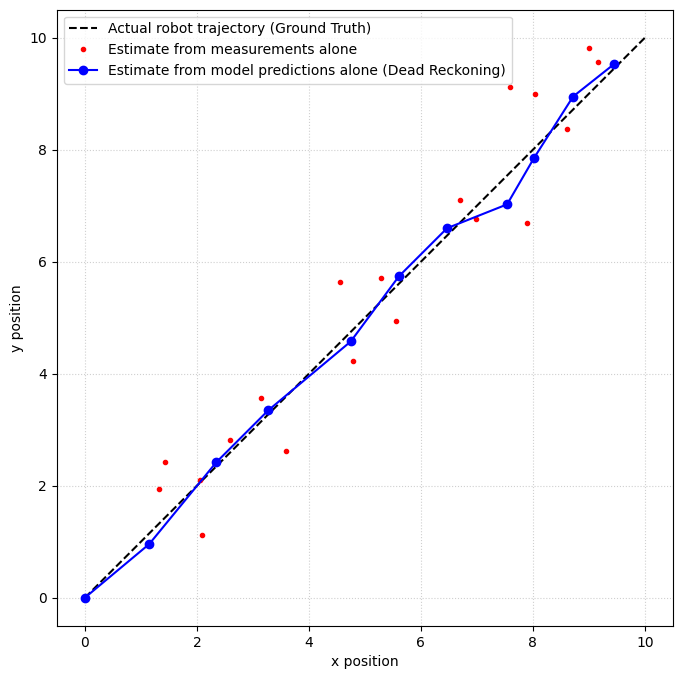

In [2]:
# Definizione dello stato e parametri temporali
# state = [x_pos, y_pos]
num_data = 20
ground_truth_x = np.linspace(0, 10, num=num_data + 1)
ground_truth_y = ground_truth_x.copy() # Traiettoria ideale diagonale: x = y

# 1. Simulazione della dinamica con rumore di processo (Dead Reckoning)
x_0, y_0 = 0, 0
xs, ys = [0], [0]
dynamics_noise_x_var = 0.3
dynamics_noise_y_var = 0.3
for _ in range(10):
    v_x, v_y = 1.0, 1.0
    # In numpy np.random.normal accetta come "scale" la deviazione standard
    noise_x = np.random.normal(loc=0.0, scale=dynamics_noise_x_var)
    noise_y = np.random.normal(loc=0.0, scale=dynamics_noise_y_var)
    new_x = xs[-1] + v_x + noise_x
    new_y = ys[-1] + v_y + noise_y
    xs.append(new_x)
    ys.append(new_y)
    
# 2. Simulazione delle misure rumorose del sensore
measurement_noise_x_var = 0.75
measurement_noise_y_var = 0.6
noise_x = np.random.normal(loc=0.0, scale=measurement_noise_x_var, size=num_data-1)
noise_y = np.random.normal(loc=0.0, scale=measurement_noise_y_var, size=num_data-1)
measurement_x = np.linspace(1, 10, num=num_data-1) + noise_x
measurement_y = np.linspace(1, 10, num=num_data-1) + noise_y

# Confronto tra traiettoria reale (Ground Truth), misure e sola dinamica
plt.figure(figsize=(8, 8))
plt.plot(ground_truth_x, ground_truth_y, 'k--', label='Actual robot trajectory (Ground Truth)')
plt.plot(measurement_x, measurement_y, 'r.', label='Estimate from measurements alone')
plt.plot(xs, ys, 'b-o', label='Estimate from model predictions alone (Dead Reckoning)')
plt.xlabel('x position')
plt.ylabel('y position')
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Analisi del grafico:
* **Dead Reckoning (linea blu):** la dinamica da sola integra lo spostamento in avanti nel tempo ma accumula errore ad ogni passo a causa del rumore sulle ruote, allontanandosi dalla rotta reale.
* **Misure (puntini rossi):** non accumulano deriva a lungo termine, ma ballano vistosamente attorno alla linea vera.
* **Il nostro obiettivo con il Filtro di Kalman:** ottenere una stima migliore fondendo insieme la dinamica e le misure dei sensori!

---
# Passo 8: Scrittura ed Implementazione delle Funzioni `predict` e `update`

Nel codice originale del notebook trovi due funzioni vuote con il commento `# TODO Need to update`.
Inoltre, il testo originale raccomanda:
> *"To multiply a 2D matrix and a 1D vector, use 'np.dot()' and not the '*' operator"*

In Python moderno possiamo usare indifferentemente:
* L'operatore **`@`** (es. `A @ mu`), che è l'operatore nativo per il prodotto matriciale;
* La funzione **`np.dot(A, mu)`**.

*(Entrambi eseguono il corretto prodotto riga per colonna dell'algebra lineare).*

Ecco l'implementazione completa e verificata:

In [3]:
def predict(A, B, Q, mu_t, u_t, Sigma_t):
    """
    Passo di Predizione:
    1. bar_mu_t = A * mu_{t-1} + B * u_t
    2. bar_Sigma_t = A * Sigma_{t-1} * A^T + Q
    """
    predicted_mu = A @ mu_t + B @ u_t
    predicted_Sigma = A @ Sigma_t @ A.T + Q
    return predicted_mu, predicted_Sigma

In [4]:
def update(H, R, z, predicted_mu, predicted_Sigma):
    """
    Passo di Aggiornamento (Update):
    1. Residuo medio: delta_mu = z - H * bar_mu
    2. Residuo covarianza: delta_Sigma = H * bar_Sigma * H^T + R
    3. Guadagno di Kalman: K = bar_Sigma * H^T * inv(delta_Sigma)
    4. Belief aggiornato:
       mu = bar_mu + K * delta_mu
       Sigma = bar_Sigma - K * H * bar_Sigma
    """
    # 1. Residuo di predizione
    residual_mean = z - H @ predicted_mu
    
    # 2. Covarianza del residuo
    residual_covariance = H @ predicted_Sigma @ H.T + R
    
    # 3. Guadagno di Kalman
    kalman_gain = predicted_Sigma @ H.T @ np.linalg.inv(residual_covariance)
    
    # 4. Aggiornamento stima e covarianza
    updated_mu = predicted_mu + kalman_gain @ residual_mean
    updated_Sigma = predicted_Sigma - kalman_gain @ H @ predicted_Sigma
    
    return updated_mu, updated_Sigma

---
# Passo 9: Esecuzione del Filtro di Kalman sul Robot

Ora eseguiamo l'intero ciclo del Filtro di Kalman per tutti i passi temporali del nostro Duckiebot:
1. Inizializziamo le matrici $\mu_0$, $\Sigma_0$, $A$, $B$, $Q$, $H$, $R$.
2. Per ogni passo temporale:
   * Chiamiamo `predict` per proiettare la posizione in avanti con il comando $\mathbf{u}_t = [1, 1]^T$.
   * Simuliamo la lettura del sensore $\mathbf{z}$.
   * Chiamiamo `update` per fondere la lettura e correggere la posizione.
   * Memorizziamo le stime per il grafico finale.

In [5]:
# Inizializzazione del problema
mu_0 = np.array([0, 0])
Sigma_0 = np.array([[0.1, 0],
                     [0, 0.1]]) # Siamo molto certi del belief iniziale bel_0
A = np.array([[1, 0],
              [0, 1]])
B = np.array([[1, 0],
              [0, 1]])
Q = np.array([[dynamics_noise_x_var, 0],
              [0, dynamics_noise_x_var]])
H = np.array([[1, 0],
              [0, 1]])
R = np.array([[measurement_noise_x_var, 0],
              [0, measurement_noise_y_var]])

# Liste per salvare le misure e le posizioni filtrate per il plotting
measurements = []
filtered_mus = []

# Esecuzione del Filtro di Kalman per ciascun passo temporale
mu_current = mu_0.copy()
Sigma_current = Sigma_0.copy()
for i in range(num_data-1):
    u_t = np.array([1, 1])
    
    # 1. Predict step
    predicted_mu, predicted_Sigma = predict(A, B, Q, 
                                            mu_current, u_t, 
                                            Sigma_current)
    
    # 2. Get measurement (nel mondo reale proviene dai sensori hardware)
    measurement_noise_x = np.random.normal(loc=0.0, scale=measurement_noise_x_var)
    measurement_noise_y = np.random.normal(loc=0.0, scale=measurement_noise_y_var)
    measurement_x_new = ground_truth_x[i+1] + measurement_noise_x
    measurement_y_new = ground_truth_x[i+1] + measurement_noise_y
    z = np.array([measurement_x_new, measurement_y_new])
    
    # 3. Update step
    mu_current, Sigma_current = update(H, R, z, 
                                       predicted_mu, 
                                       predicted_Sigma)
    
    # Memorizziamo le misure e mu_current per visualizzarle
    measurements.append([measurement_x_new, measurement_y_new])
    filtered_mus.append(mu_current)

# Convertiamo le liste in array numpy per il grafico
measurements = np.array(measurements)
filtered_mus = np.array(filtered_mus)
print("Filtro di Kalman eseguito con successo!")

Filtro di Kalman eseguito con successo!


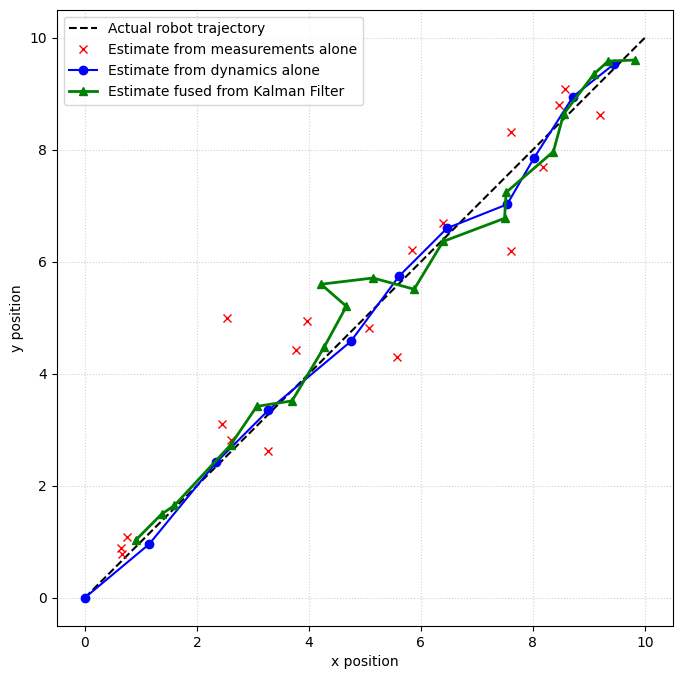

In [6]:
# Visualizziamo i risultati
plt.figure(figsize=(8,8))
plt.plot(ground_truth_x, ground_truth_y, 'k--', label='Actual robot trajectory')
plt.plot(measurements[:,0], measurements[:,1], 'rx', label='Estimate from measurements alone')
plt.plot(xs, ys, 'b-o', label='Estimate from dynamics alone')
plt.plot(filtered_mus[:,0], filtered_mus[:,1], 'g-^', linewidth=2, label='Estimate fused from Kalman Filter')
plt.xlabel('x position')
plt.ylabel('y position')
plt.legend([
    'Actual robot trajectory', 
    'Estimate from measurements alone', 
    'Estimate from dynamics alone', 
    'Estimate fused from Kalman Filter'
])
plt.gca().set_aspect('equal', adjustable='box')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

---
# Passo 10: Analisi e Valutazione dei Risultati

Come puoi osservare chiaramente dal grafico:
1. La traiettoria stimata dal **Filtro di Kalman (linea verde)** si trova vicinissima alla traiettoria reale ideale (**linea nera tratteggiata**).
2. Ha rimosso le violente oscillazioni casuali delle sole misure (**crocette rosse**).
3. Non si perde per strada come fa la pura odometria (**linea blu**).

Possiamo misurare quantitativamente questo miglioramento plottando l'errore euclideo di localizzazione:
$$e_t = \| \mathbf{x}_{\text{stimato}} - \mathbf{x}_{\text{reale}} \|$$

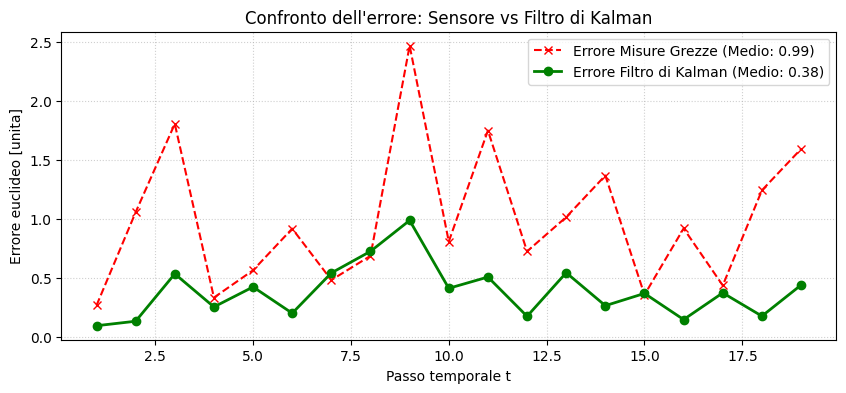

In [8]:
gt_pts = np.column_stack((ground_truth_x[2:], ground_truth_x[2:]))
err_sensor = np.linalg.norm(measurements - gt_pts, axis=1)
err_kf = np.linalg.norm(filtered_mus - gt_pts, axis=1)

plt.figure(figsize=(10, 4))
plt.plot(range(1, num_data), err_sensor, 'r--x', label=f'Errore Misure Grezze (Medio: {np.mean(err_sensor):.2f})')
plt.plot(range(1, num_data), err_kf, 'g-o', linewidth=2, label=f'Errore Filtro di Kalman (Medio: {np.mean(err_kf):.2f})')
plt.xlabel('Passo temporale t')
plt.ylabel('Errore euclideo [unita]')
plt.title('Confronto dell\'errore: Sensore vs Filtro di Kalman')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

---
# Tabella di Sintesi di Tutte le Matrici del Filtro di Kalman

| Simbolo | Nome | Significato Fisico sul Duckiebot | Valore nel Notebook |
| :---: | :--- | :--- | :--- |
| $\mathbf{x}_t$ | Vettore di Stato | Coordinate reali del robot sul pavimento $[x, y]^T$ | Vettore $2 \times 1$ |
| $\mu_t$ | Media dello Stato | La migliore stima del punto in cui si trova il robot | Inizializzato a $[0, 0]^T$ |
| $\Sigma_t$ ($P_t$) | Covarianza dello Stato | Incertezza e forma dell'ellisse di dubbio su $x$ e $y$ | $\begin{bmatrix} 0.1 & 0 \\ 0 & 0.1 \end{bmatrix}$ |
| $A$ | Transizione di Stato | Come evolve il robot per inerzia/fisica naturale | $\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$ (fermo resta fermo) |
| $\mathbf{u}_t$ | Vettore di Controllo | Comandi di velocità inviati alle ruote $[v_x, v_y]^T$ | $[1, 1]^T$ |
| $B$ | Matrice di Controllo | Converte le velocità in centimetri percorsi ($\times \Delta t$) | $\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$ |
| $Q$ | Covarianza di Processo | Entità dello slittamento delle ruote e attrito pavimento | $\begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$ |
| $\mathbf{z}_t$ | Vettore di Misura | Lettura grezza restituita dai sensori esterni | $[z_x, z_y]^T$ |
| $H$ | Matrice di Misura | Traduttore che proietta lo stato nello spazio dei sensori | $\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$ |
| $R$ | Covarianza di Misura | Entità del rumore/imprecisione dichiarata dei sensori | $\begin{bmatrix} 0.75 & 0 \\ 0 & 0.6 \end{bmatrix}$ |
| $\delta_\mu$ | Innovazione (Residuo) | Sorpresa: discrepanza tra misura e predizione | $\mathbf{z}_t - H \bar{\mu}_t$ |
| $K_t$ | Kalman Gain | Peso di fiducia assegnato al sensore vs movimento | Calcolato ad ogni istante |

---

### Prossimo Passo: Dal lineare al non lineare
Hai completato con successo lo studio e la sperimentazione del **Filtro di Kalman** lineare!
Nel mondo reale molti sensori e robot hanno relazioni non lineari (ad esempio angoli di rotazione $\theta$, curvatura delle ruote, o misure multimodali).
Per affrontare questi casi, il passo successivo è studiare:
* **[Particle Filters (Filtro a Particelle)](../02-particle-filter/particle-filter.ipynb)**
* **[EKF Localization (Extended Kalman Filter)](../04-ekf-localization/ekf_localization.ipynb)**